In [1]:
from anemone.experiment import *
from anemone.forwards import *
from anemone.inversion import *
import matplotlib.pyplot as plt

In [2]:
tx = Loop.square(40)
rx = Receiver()
waveform = Waveform.example()
# recfilter = FilterChain([ButterworthFilter(2.4e5,1),
#                          ButterworthFilter(6.2e5,1),
#                          ButterworthFilter(4.5e5,1)])

In [3]:
def logify_forward(cls):
    class LogFwr(cls):
        def __call__(self, *args, **kwargs):
            return super().__call__(*args, **kwargs).log10()
    return LogFwr

LFL6 = logify_forward(ForwardLaplace6)

In [4]:
times = torch.logspace(-5,-2, 32)
fwrTD = LFL6(tx, rx,times,waveform=waveform)

/home/matt/repositories/anemone/src/anemone/experiment/experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [5]:
def compute_relstd(t_gates, dbdt, noise_slope_exponent=-0.5, noise_level_at_1ms=1e-8, current=1., relative_noise=0.03):
    b = noise_level_at_1ms/(1e-3**noise_slope_exponent)
    abs_noise = b*(t_gates**noise_slope_exponent)
    y = dbdt*current
    std_rel = abs_noise/y
    relstd_tot = torch.sqrt(std_rel**2 + relative_noise**2)
    return relstd_tot

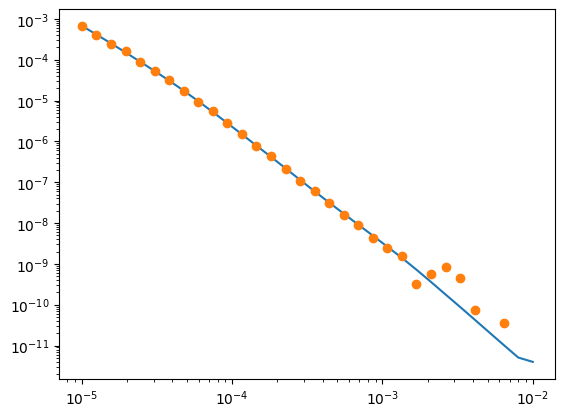

In [6]:
rho = torch.tensor([20, 80, 40])
thk = torch.tensor([30,40.])
mod_true = LogResistivity.few_layers(rho, thk)


dbdt_true = 10**fwrTD(rho, thk)
d_relerr = compute_relstd(fwrTD.times, dbdt_true, current=10.)
d_err = torch.log10(1. + d_relerr)
d_obs = dbdt_true + dbdt_true * torch.randn_like(dbdt_true) * d_relerr


plt.figure()
plt.loglog(fwrTD.times, dbdt_true, '-', label='Observed')
plt.loglog(fwrTD.times, d_obs, 'o', label='Observed')

d_obs = torch.abs(d_obs).log10()

In [7]:
class ParamDependentDamping1(BaseInversion):
    max_step                         = 3
    min_step                         = 0.1
    damping_factor                   = 729/5000
    damp_inc                         = 3.
    damp_dec                         = 9.
    damp_initmax                     = 1e6  
    vertical_smoothness              = 0.1
        
    @property
    def damp_matrix(self):
        diag_GTG = self.GtG.diagonal()
        damp = torch.empty_like(diag_GTG)
        for i,pslice in enumerate(self.model.pslice):
            max_GTG = diag_GTG[pslice].max()
            damp[pslice] =  max_GTG*self.damp_factors[i]
        damp = torch.clamp(damp, min=1., max=self.damp_initmax)
        return damp*self.Imod

    def setup_matrices(self):
        self.mvec = self.m*1.
        n_ptypes = len(self.model.pslice)
        self.Cm = torch.eye(len(self.mvec)-n_ptypes, dtype=torch.float64) / (torch.log(torch.tensor(1 + self.vertical_smoothness, dtype=torch.float64)) ** 2)
        self.damp_factors = torch.ones(n_ptypes, dtype=torch.float64) * self.damping_factor
        self.max_step = torch.ones(n_ptypes, dtype=torch.double)*self.max_step
        self.min_step = torch.ones(n_ptypes, dtype=torch.double)*self.min_step
        self.set_device(self.mvec.device)
        self.H = self.model.H().to(torch.double)
        self.HtH = self.H.T @ self.Cm @ self.H
        super().setup_matrices()


    @property
    def stop_inversion(self):
        if self.iteration > 1 and self.misfits[-1]>self.misfits[-2]>self.misfits[-3]==min(self.misfits):
            return True
        else: return super().stop_inversion
    
    def check_dM(self, dM):
        dM_abs = torch.abs(dM)
        test_damping = [True]*len(self.model.pslice)
        for i,pslice in enumerate(self.model.pslice):
            if dM_abs[pslice].max()>self.max_step[i]:
                self.damp_factors[i] *= self.damp_inc
            elif dM_abs[pslice].min()<self.min_step[i]:
                self.damp_factors[i] /= self.damp_dec
            else:
                test_damping[i] = False
        return any(test_damping)
    
    def adjust_stepsize(self):
        if self.misfits[-1]>self.misfits[-2]:
            self.log("Misfit increased, reducing step size")
            for i,pslice in enumerate(self.model.pslice):
                self.max_step[pslice] -= 1.
                self.damp_factors[i] *= self.damp_dec
        else:
            self.log("Misfit decreased, increasing step size")
            for i,pslice in enumerate(self.model.pslice):
                self.max_step[pslice] += 0.5
        for i,pslice in enumerate(self.model.pslice):
            if self.max_step[i] < self.min_step[i]:
                self.max_step[i] = self.min_step[i]
                    
    def run_iteration(self):
        dM   = self.calc_dm()
        self.mvec = self.model.make_physical(self.mvec + dM)
        self.iteration += 1
        self.misfits.append(self.misfit())
        self.log("{:03d}\tmisfit:\t{:2.2f}\tdata misfit: {:2.2f}".format(self.iteration, self.misfits[-1], super().misfit()))
        self.adjust_stepsize()


    def calc_dm(self):
        r_data  = self.G.T @ self.Cdi @ (self.data_observed-self.data_predicted)
        r_data -= self.HtH @ self.mvec.to(torch.double)
        Aown = self.GtG + self.damp_matrix + self.HtH
        dM = solve(Aown, r_data)
        damping_attempts = 0
        while self.check_dM(dM) and damping_attempts < 1000:
            Aown = self.GtG + self.damp_matrix + self.HtH
            dM = solve(Aown, r_data)
            damping_attempts += 1
        print('damping attempts:', damping_attempts)
        return dM

    def misfit(self):
        r_mod = - self.H @ self.mvec
        d_data = self.data_observed - self.data_predicted
        d = d_data.T @ self.Cdi @ d_data
        r = r_mod.T @ self.Cm @ r_mod
        return torch.sqrt((d + r) / (self.nD+ self.nM))

/home/matt/repositories/dolphinv/src/dolphinv/inversion.py:220: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3683.)
  d = d_data.T @ self.Cdi @ d_data


max GTG for pslice 0: 205.15119645247046
damping attempts: 1
001	misfit:	4.03	data misfit:	5.65
max GTG for pslice 0: 460059.7704283836
max GTG for pslice 0: 153353.2568094612
max GTG for pslice 0: 51117.7522698204
damping attempts: 5
002	misfit:	3.69	data misfit:	5.16
max GTG for pslice 0: 17100.94235287589
damping attempts: 1
003	misfit:	3.04	data misfit:	4.25
max GTG for pslice 0: 5960.620795741027
damping attempts: 1
004	misfit:	2.14	data misfit:	2.99
damping attempts: 1
005	misfit:	0.80	data misfit:	1.04
damping attempts: 1
006	misfit:	0.73	data misfit:	0.93
damping attempts: 1
007	misfit:	0.73	data misfit:	0.93
misfit change is less than 0.001


[<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>]

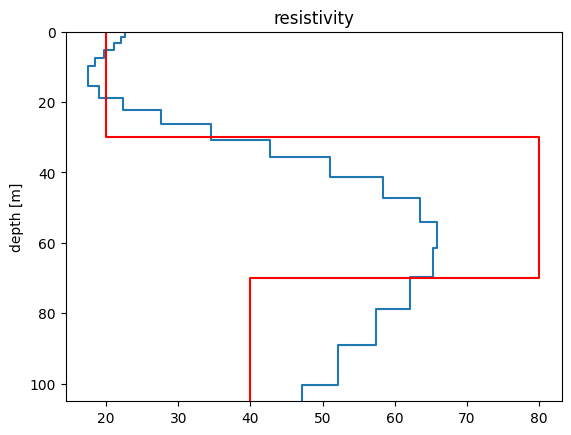

In [8]:
res_start = LogResistivity.smooth(torch.ones(31, dtype=torch.double)*50, torch.cumsum(torch.logspace(0.2,1.5,30), 0))
inv = ParamDependentDamping(d_obs, d_err, res_start, fwrTD)
inv.vertical_smoothness = 0.1
res_mod = inv.invert(iter_cap=10)
ax = res_mod.plot()
mod_true.plot(axs=ax, color='red', label='True model')

In [8]:
res_start = LogResistivity.few_layers([torch.tensor([20,21,20], dtype=torch.double)], torch.tensor([30,30]))
inv = Tikhonov(d_obs, d_err, res_start, fwrTD)
inv.data_misfit_acceptance_threshold = 0.1
res_mod = inv.invert(iter_cap=100)

001	misfit:	2.82
002	misfit:	1.43
003	misfit:	1.00
004	misfit:	0.84
005	misfit:	0.79
006	misfit:	0.78
007	misfit:	0.78
008	misfit:	0.78
misfit change is less than 0.001


[<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>]

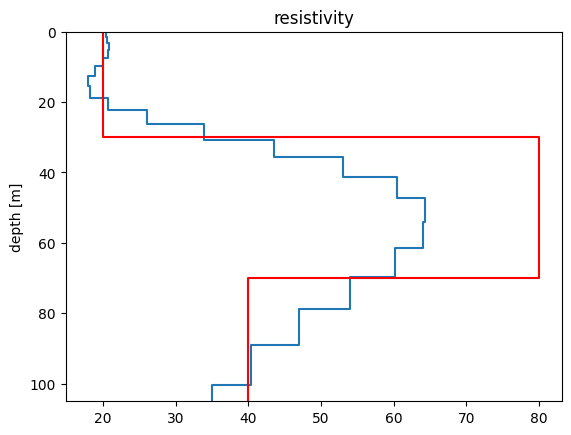

In [8]:
ax = res_mod.plot()
mod_true.plot(axs=ax, color='red', label='True model')

In [10]:
class ParamDependentDamping1(BaseInversion):
    max_step                         = 3
    min_step                         = 0.1
    damping_factor                   = 729/5000
    damp_inc                         = 3.
    damp_dec                         = 9.
    damp_initmax                     = 1e6  
    vertical_smoothness              = 0.1
        
    @property
    def damp_matrix(self):
        diag_GTG = self.GtG.diagonal()
        damp = torch.empty_like(diag_GTG)
        for i,pslice in enumerate(self.model.pslice):
            max_GTG = diag_GTG[pslice].max()
            damp[pslice] =  max_GTG*self.damp_factors[i]
        damp = torch.clamp(damp, min=1., max=self.damp_initmax)
        return damp*self.Imod

    def setup_matrices(self):
        self.mvec = self.m*1.
        n_ptypes = len(self.model.pslice)
        self.Cm = torch.eye(len(self.mvec)-n_ptypes, dtype=torch.float64) / (torch.log(torch.tensor(1 + self.vertical_smoothness, dtype=torch.float64)) ** 2)
        self.damp_factors = torch.ones(n_ptypes, dtype=torch.float64) * self.damping_factor
        self.max_step = torch.ones(n_ptypes, dtype=torch.double)*self.max_step
        self.min_step = torch.ones(n_ptypes, dtype=torch.double)*self.min_step
        self.set_device(self.mvec.device)
        self.H = self.model.H().to(torch.double)
        self.HtH = self.H.T @ self.Cm @ self.H
        super().setup_matrices()


    @property
    def stop_inversion(self):
        if self.iteration > 1 and self.misfits[-1]>self.misfits[-2]>self.misfits[-3]==min(self.misfits):
            return True
        else: return super().stop_inversion
    
    def check_dM(self, dM):
        dM_abs = torch.abs(dM)
        test_damping = [True]*len(self.model.pslice)
        for i,pslice in enumerate(self.model.pslice):
            if dM_abs[pslice].max()>self.max_step[i]:
                self.damp_factors[i] *= self.damp_inc
            elif dM_abs[pslice].min()<self.min_step[i]:
                self.damp_factors[i] /= self.damp_dec
            else:
                test_damping[i] = False
        return any(test_damping)
    
    def adjust_stepsize(self):
        if self.misfits[-1]>self.misfits[-2]:
            self.log("Misfit increased, reducing step size")
            for i,pslice in enumerate(self.model.pslice):
                self.max_step[pslice] -= 1.
                self.damp_factors[i] *= self.damp_dec
        else:
            self.log("Misfit decreased, increasing step size")
            for i,pslice in enumerate(self.model.pslice):
                self.max_step[pslice] += 0.5
        for i,pslice in enumerate(self.model.pslice):
            if self.max_step[i] < self.min_step[i]:
                self.max_step[i] = self.min_step[i]
                    
    def run_iteration(self):
        dM   = self.calc_dm()
        self.mvec = self.model.make_physical(self.mvec + dM)
        self.iteration += 1
        self.misfits.append(self.misfit())
        self.log("{:03d}\tmisfit:\t{:2.2f}\tdata misfit: {:2.2f}".format(self.iteration, self.misfits[-1], super().misfit()))
        self.adjust_stepsize()


    def calc_dm(self):
        r_data  = self.G.T @ self.Cdi @ (self.data_observed-self.data_predicted)
        r_data -= self.HtH @ self.mvec.to(torch.double)
        Aown = self.GtG + self.damp_matrix + self.HtH
        dM = solve(Aown, r_data)
        damping_attempts = 0
        while self.check_dM(dM) and damping_attempts < 100:
            Aown = self.GtG + self.damp_matrix + self.HtH
            dM = solve(Aown, r_data)
            damping_attempts += 1
        print('damping attempts:', damping_attempts)
        return dM

    def misfit(self):
        r_mod = - self.H @ self.mvec
        d_data = self.data_observed - self.data_predicted
        d = d_data.T @ self.Cdi @ d_data
        r = r_mod.T @ self.Cm @ r_mod
        return torch.sqrt((d + r) / (self.nD+ self.nM))

array([<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>,
       <Axes: title={'center': 'phi'}>, <Axes: title={'center': 'tau'}>,
       <Axes: title={'center': 'c'}>], dtype=object)

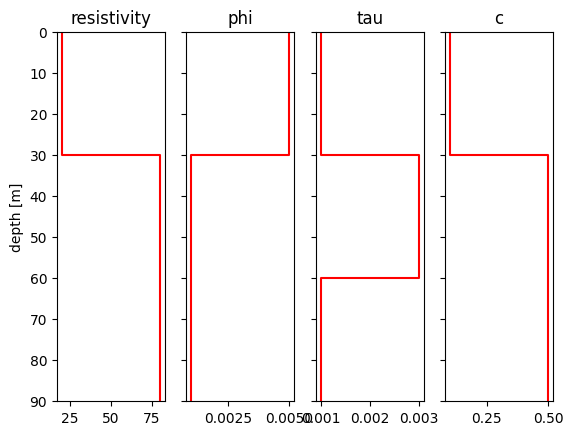

In [15]:
mpa1 = LogMPA.few_layers([
    torch.tensor([20., 80., 80.]),
    torch.tensor([0.005, 0.001, 0.001]),
    torch.tensor([1e-4, 3e-4, 1e-4])*10.,
    torch.tensor([0.1, 0.5, 0.5])
],  torch.tensor([30, 30]))
mpa1.set_device(torch.double)


mpa1.plot(label='MPA2 True Model', color='red')

In [20]:
fwrmpa = ForwardLaplace6.mpa(tx, rx, fwrTD.times, waveform=waveform)
# mpa = logify_forward(fwrmpa.__class__)
# fwrmpa = mpa(tx, rx, fwrTD.times, waveform=waveform)
#fwrmpa = ForwardLaplace6.mpa(tx, rx, fwrTD.times, waveform=waveform, filterfunc=recfilter)

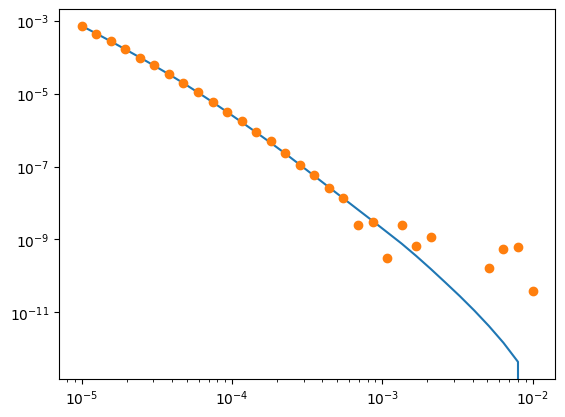

In [23]:
dbdt_true = fwrmpa(*mpa1.mod)
d_relerr = compute_relstd(fwrTD.times, dbdt_true, current=10.)
d_obs = dbdt_true + dbdt_true * torch.randn_like(dbdt_true) * d_relerr
d_err = dbdt_true*d_relerr

plt.figure()
plt.loglog(fwrmpa.times, dbdt_true, '-', label='Observed')
plt.loglog(fwrmpa.times, d_obs, 'o', label='Observed')

In [26]:
res_start = LogMPA.smooth([torch.ones(31)*10,
                           torch.ones(31)*0.005,
                           torch.ones(31)*5e-4,
                           torch.ones(31)*0.25
                           ], torch.cumsum(torch.logspace(0,1,30), 0))
res_start.set_device(torch.double)

inv = ParamDependentDamping1(d_obs, d_err, res_start, fwrmpa)
inv.data_misfit_acceptance_threshold = 0.1
inv.vertical_smoothness = 0.2
res_mpa = inv.invert(iter_cap=10)

damping attempts: 1000
001	misfit:	6.90	data misfit: 15.22
Misfit decreased, increasing step size
damping attempts: 1000
002	misfit:	1.36	data misfit: 3.00
Misfit decreased, increasing step size
damping attempts: 1000
003	misfit:	0.50	data misfit: 1.05
Misfit decreased, increasing step size
damping attempts: 1000
004	misfit:	0.47	data misfit: 1.02
Misfit decreased, increasing step size
damping attempts: 1000
005	misfit:	0.47	data misfit: 1.01
Misfit decreased, increasing step size
damping attempts: 1000
006	misfit:	0.47	data misfit: 1.01
Misfit decreased, increasing step size
misfit change is less than 0.001


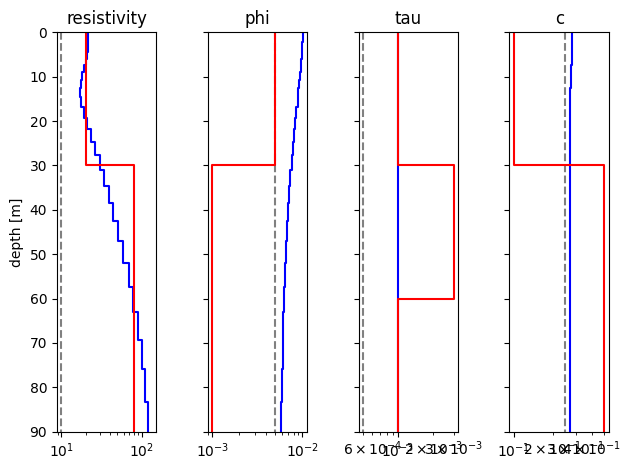

In [27]:
axs = res_mpa.plot(label='MPA Inversion Result', color='blue')
res_start.plot(axs=axs, color='gray', linestyle='--', label='starting model')
mpa1.plot(axs=axs, color='red', label='MPA True Model')

for ax in axs:
    ax.set_xscale('log')
plt.tight_layout()